# 02 — Note-Level Preprocessing (Audio–Sheet Music)

Notebook ini mengubah pasangan **halaman ↔ segmen audio 5 detik** menjadi pasangan **crop notehead ↔ window audio di sekitar onset note**.

Tujuan:
- Setiap contoh training berisi satu potongan gambar not dan satu potongan audio yang benar-benar correspond.
- Crop gambar 160×200 px di sekitar notehead, tetap menyertakan garis staff.
- Window audio 42 frame (≈2,1 detik pada 20 fps) di sekitar onset note.
- Train memakai maksimal 2 performance per notehead; val/test memakai semua performance valid.
- Artefak page-level dari notebook `01` tidak diubah.

Output utama:
- `score_crops_{split}.npy` — `[N, 200, 160, 1]` uint8
- `audio_windows_{split}.npy` — `[N, 42, 92]` float16
- `noteheads_{split}.csv`, `windows_{split}.csv`, `pairs_note_{split}.csv`
- `norm_stats_note.json`, `coverage_note_level.csv`, `preprocess_summary_note.json`


## 1. Setup dan validasi input

In [1]:
import json
import re
import random
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 80)
%matplotlib inline

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

FPS = 20
CROP_W = 160
CROP_H = 200
WIN_FRAMES = 42
TRAIN_PERFS_PER_NOTE = 2
NEG_PER_POS = 1
SPEC_BINS = 92

PROJECT = Path(r"C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT")
BASE = PROJECT / "msmd_aug_v1-1_no-audio"
DATA = PROJECT / "data"
PROC = DATA / "processed"
FIG = PROJECT / "reports" / "figures"
REP = PROJECT / "reports"
for d in [PROC, FIG, REP]:
    d.mkdir(parents=True, exist_ok=True)

with open(PROC / "norm_stats.json", encoding="utf-8") as f:
    BASE_NORM = json.load(f)
SPEC_MEAN = np.asarray(BASE_NORM["audio"]["spec_mean"], dtype=np.float32)
SPEC_STD = np.asarray(BASE_NORM["audio"]["spec_std"], dtype=np.float32)
assert SPEC_MEAN.shape == (SPEC_BINS,), SPEC_MEAN.shape
assert SPEC_STD.shape == (SPEC_BINS,), SPEC_STD.shape

print("Project :", PROJECT)
print("Output  :", PROC)
print("Crop    :", CROP_H, "x", CROP_W)
print("Window  :", WIN_FRAMES, "frames @", FPS, "fps")
print("Audio stats loaded:", SPEC_MEAN.shape)


Project : C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT
Output  : C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\data\processed
Crop    : 200 x 160
Window  : 42 frames @ 20 fps
Audio stats loaded: (92,)


In [2]:
subset = pd.read_csv(DATA / "subset_pieces.csv")
perfs = pd.read_csv(DATA / "subset_performances.csv")
splits = pd.read_csv(DATA / "splits.csv")

assert set(subset["piece"]) == set(perfs["piece"])
assert len(subset) == subset["piece"].nunique()

perfs_by_piece = {p: g.to_dict("records") for p, g in perfs.groupby("piece")}
composer_by_piece = dict(zip(subset["piece"], subset["composer"]))
work_group_by_piece = dict(zip(subset["piece"], subset["work_group"]))
split_by_piece = dict(zip(subset["piece"], subset["split"]))


def score_dirs(piece):
    sdir = BASE / piece / "scores"
    if not sdir.is_dir():
        return []
    return sorted([d for d in sdir.iterdir() if d.is_dir()])


def has_mung(piece):
    for sd in score_dirs(piece):
        mdir = sd / "mung"
        if mdir.is_dir() and any(mdir.glob("*.xml")):
            return True
    return False


no_mung = [p for p in subset["piece"] if not has_mung(p)]
EXCLUDED_PIECES = set(no_mung)
subset_note = subset[~subset["piece"].isin(EXCLUDED_PIECES)].copy()
perfs_note = perfs[~perfs["piece"].isin(EXCLUDED_PIECES)].copy()

print("Piece total          :", len(subset))
print("Piece dengan MuNG    :", len(subset_note))
print("Piece dikecualikan   :", no_mung)
print()
print(subset_note.groupby("split").size().rename("n_piece"))
print()
print(perfs_note.groupby("split").size().rename("n_performance"))

for a, b in combinations(["train", "val", "test"], 2):
    wa = set(subset_note.loc[subset_note["split"] == a, "work_group"])
    wb = set(subset_note.loc[subset_note["split"] == b, "work_group"])
    assert not (wa & wb), f"Leakage work_group antara {a} dan {b}"
print("Split check: work_group disjoint -> PASS")


Piece total          : 25
Piece dengan MuNG    : 24
Piece dikecualikan   : ['GobbaertsL__Les_Etoiles_dOr_No1__Les_Etoiles_dOr_No1']

split
test      3
train    17
val       4
Name: n_piece, dtype: int64

split
test     12
train    68
val      16
Name: n_performance, dtype: int64
Split check: work_group disjoint -> PASS


## 2. Helper: halaman, crop, dan MuNG

- PNG dan XML dipasangkan per score directory berdasarkan nama stem.
- Crop berpusat di notehead; jika keluar halaman, padding putih.
- Notehead dengan `tied=1` tetap dipakai hanya jika punya onset valid.


In [3]:
def page_items(piece):
    items = []
    page_num = 0
    for sd in score_dirs(piece):
        pngs = sorted((sd / "img").glob("*.png")) if (sd / "img").is_dir() else []
        mungs = sorted((sd / "mung").glob("*.xml")) if (sd / "mung").is_dir() else []
        mung_by_stem = {p.stem: p for p in mungs}
        for i, png in enumerate(pngs):
            page_num += 1
            mung = mung_by_stem.get(png.stem)
            if mung is None and len(mungs) == len(pngs):
                mung = mungs[i]
            items.append({"page_num": page_num, "png": png, "mung": mung, "score_dir": sd})
    return items


def load_gray(path):
    im = Image.open(path).convert("RGBA")
    bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
    return np.asarray(Image.alpha_composite(bg, im).convert("L"), dtype=np.uint8)


def crop_notehead(page_gray, cx, cy, crop_w=CROP_W, crop_h=CROP_H):
    h, w = page_gray.shape
    x0 = int(round(cx - crop_w / 2.0))
    y0 = int(round(cy - crop_h / 2.0))
    x1 = x0 + crop_w
    y1 = y0 + crop_h

    pad_l = max(0, -x0)
    pad_t = max(0, -y0)
    pad_r = max(0, x1 - w)
    pad_b = max(0, y1 - h)

    xs, ys = max(0, x0), max(0, y0)
    xe, ye = min(w, x1), min(h, y1)
    crop = page_gray[ys:ye, xs:xe]

    if pad_l or pad_t or pad_r or pad_b:
        crop = np.pad(crop, ((pad_t, pad_b), (pad_l, pad_r)), constant_values=255)

    if crop.shape != (crop_h, crop_w):
        out = np.full((crop_h, crop_w), 255, dtype=np.uint8)
        oh, ow = min(crop_h, crop.shape[0]), min(crop_w, crop.shape[1])
        out[:oh, :ow] = crop[:oh, :ow]
        crop = out

    pad_frac = (pad_l + pad_t + pad_r + pad_b) / float(crop_w + crop_h)
    return crop, {
        "pad_left": pad_l,
        "pad_top": pad_t,
        "pad_right": pad_r,
        "pad_bottom": pad_b,
        "pad_frac": pad_frac,
    }


def parse_mung_noteheads(mung_path):
    tree = ET.parse(mung_path)
    out = []
    for obj in tree.getroot().iter("CropObject"):
        if obj.findtext("ClassName") != "notehead-full":
            continue
        data = {d.get("key"): d.text for d in obj.iter("DataItem")}
        pitch_raw = data.get("midi_pitch_code")
        if pitch_raw in (None, ""):
            continue
        top = int(obj.findtext("Top"))
        left = int(obj.findtext("Left"))
        width = int(obj.findtext("Width"))
        height = int(obj.findtext("Height"))
        out.append({
            "mung_id": obj.findtext("Id"),
            "top": top,
            "left": left,
            "width": width,
            "height": height,
            "cx": left + width / 2.0,
            "cy": top + height / 2.0,
            "pitch": int(float(pitch_raw)),
            "tied": int(float(data.get("tied", 0) or 0)),
            "data": data,
        })
    return out


def extract_window(spec_norm, onset_frame, win=WIN_FRAMES):
    n_frames = spec_norm.shape[0]
    start = onset_frame - win // 2
    end = start + win
    out = np.zeros((win, SPEC_BINS), dtype=np.float16)
    x0, x1 = max(0, start), min(n_frames, end)
    if x1 > x0:
        seg = spec_norm[x0:x1]
        off = x0 - start
        out[off:off + seg.shape[0]] = seg.astype(np.float16)
    return out, {
        "start_frame": int(start),
        "end_frame": int(end),
        "pad_left": int(max(0, -start)),
        "pad_right": int(max(0, end - n_frames)),
        "n_frames": int(n_frames),
    }


print("Helper siap.")


Helper siap.


## 3. Builder artefak per split

Fungsi `build_split` melakukan:
1. Memilih performance (train: maksimal 2; val/test: semua).
2. Memuat `notes.npy` dan `spec.npy` per performance.
3. Mem-parse MuNG per halaman dan memvalidasi `note_event_idx` + pitch.
4. Membuat crop gambar dan window audio.
5. Menyimpan tensor + index.


In [4]:
def choose_perfs(perfs_list, split):
    if split != "train":
        return list(perfs_list)

    ranked = sorted(
        perfs_list,
        key=lambda r: (
            abs((float(r["tempo"]) if pd.notna(r["tempo"]) else 1000.0) - 1000.0),
            str(r["soundfont"]),
            str(r["perf_name"]),
        ),
    )
    chosen = []
    seen_sf = set()
    for r in ranked:
        sf = str(r["soundfont"])
        if sf not in seen_sf:
            chosen.append(r)
            seen_sf.add(sf)
            if len(chosen) >= TRAIN_PERFS_PER_NOTE:
                break
    for r in ranked:
        if len(chosen) >= TRAIN_PERFS_PER_NOTE:
            break
        if all(r["perf_name"] != x["perf_name"] for x in chosen):
            chosen.append(r)
    return chosen[:TRAIN_PERFS_PER_NOTE]


def build_split(split):
    pieces = subset_note.loc[subset_note["split"] == split, "piece"].tolist()
    crop_list, crop_rows = [], []
    window_list, window_rows = [], []
    coverage_rows = []

    for piece in pieces:
        pperfs = choose_perfs(perfs_by_piece[piece], split)

        notes_by_perf = {}
        spec_by_perf = {}
        for r in pperfs:
            pf = r["perf_name"]
            fdir = Path(r["features_dir"])
            notes_by_perf[pf] = np.load(fdir / f"{pf}.flac_notes.npy")
            sp = np.load(fdir / f"{pf}.flac_spec.npy").T.astype(np.float32)
            assert sp.ndim == 2 and sp.shape[1] == SPEC_BINS, (pf, sp.shape)
            spec_by_perf[pf] = np.clip((sp - SPEC_MEAN) / SPEC_STD, -5, 5)

        pages = page_items(piece)
        n_noteheads = 0
        n_mapped = 0
        n_tied_skipped = 0
        n_missing_event = 0
        n_valid_windows = 0
        n_edge_crops = 0

        for pg in pages:
            if pg["mung"] is None:
                continue
            page_arr = load_gray(pg["png"])
            nhs = parse_mung_noteheads(pg["mung"])
            page_id = f"{piece}__p{pg['page_num']:02d}"
            n_noteheads += len(nhs)

            for nh in nhs:
                valid_windows = []
                for r in pperfs:
                    pf = r["perf_name"]
                    notes = notes_by_perf[pf]
                    idx_raw = nh["data"].get(f"{pf}_note_event_idx")
                    if idx_raw in (None, ""):
                        n_missing_event += 1
                        continue
                    try:
                        idx = int(float(idx_raw))
                    except Exception:
                        n_missing_event += 1
                        continue
                    if idx < 0 or idx >= len(notes):
                        n_missing_event += 1
                        continue
                    if int(notes[idx, 1]) != nh["pitch"]:
                        n_missing_event += 1
                        continue

                    onset_raw = nh["data"].get(f"{pf}_onset_seconds")
                    try:
                        onset_s = float(onset_raw) if onset_raw not in (None, "") else float(notes[idx, 0])
                    except Exception:
                        onset_s = float(notes[idx, 0])
                    if not np.isfinite(onset_s):
                        n_missing_event += 1
                        continue

                    spec = spec_by_perf[pf]
                    onset_frame = int(round(onset_s * FPS))
                    if onset_frame < 0 or onset_frame >= spec.shape[0]:
                        n_missing_event += 1
                        continue

                    win, win_meta = extract_window(spec, onset_frame)
                    valid_windows.append({
                        "perf_name": pf,
                        "note_event_idx": idx,
                        "onset_s": onset_s,
                        "onset_frame": onset_frame,
                        "window": win,
                        **win_meta,
                    })

                if not valid_windows:
                    if nh["tied"] == 1:
                        n_tied_skipped += 1
                    continue

                crop, pad_info = crop_notehead(page_arr, nh["cx"], nh["cy"])
                edge = int(pad_info["pad_frac"] > 0.30)
                n_edge_crops += edge
                n_mapped += 1

                mid = re.sub(r"[^A-Za-z0-9]+", "", str(nh["mung_id"])) or "0"
                notehead_id = f"{page_id}__nh{mid}"
                crop_row = len(crop_list)
                crop_list.append(crop[..., None])
                crop_rows.append({
                    "notehead_id": notehead_id,
                    "page_id": page_id,
                    "piece": piece,
                    "composer": composer_by_piece[piece],
                    "work_group": work_group_by_piece[piece],
                    "split": split,
                    "page_num": pg["page_num"],
                    "mung_id": nh["mung_id"],
                    "cx": nh["cx"],
                    "cy": nh["cy"],
                    "box_top": nh["top"],
                    "box_left": nh["left"],
                    "box_w": nh["width"],
                    "box_h": nh["height"],
                    "pitch": nh["pitch"],
                    "tied": nh["tied"],
                    "edge": edge,
                    "pad_frac": pad_info["pad_frac"],
                    "ink_ratio": float((crop < 250).mean()),
                    "png_path": str(pg["png"]),
                    "mung_path": str(pg["mung"]),
                    "crop_row": crop_row,
                })

                for vw in valid_windows:
                    window_id = f"{notehead_id}__{vw['perf_name']}__w"
                    window_row = len(window_list)
                    window_list.append(vw["window"])
                    window_rows.append({
                        "window_id": window_id,
                        "notehead_id": notehead_id,
                        "page_id": page_id,
                        "piece": piece,
                        "composer": composer_by_piece[piece],
                        "work_group": work_group_by_piece[piece],
                        "split": split,
                        "perf_name": vw["perf_name"],
                        "note_event_idx": vw["note_event_idx"],
                        "onset_s": vw["onset_s"],
                        "onset_frame": vw["onset_frame"],
                        "start_frame": vw["start_frame"],
                        "end_frame": vw["end_frame"],
                        "pad_left": vw["pad_left"],
                        "pad_right": vw["pad_right"],
                        "n_frames": vw["n_frames"],
                        "pitch": nh["pitch"],
                        "window_row": window_row,
                    })
                    n_valid_windows += 1

        coverage_rows.append({
            "piece": piece,
            "split": split,
            "n_pages": len(pages),
            "n_noteheads": n_noteheads,
            "n_mapped_noteheads": n_mapped,
            "n_tied_skipped": n_tied_skipped,
            "n_missing_event": n_missing_event,
            "n_valid_windows": n_valid_windows,
            "n_edge_crops": n_edge_crops,
            "pct_mapped": (100.0 * n_mapped / n_noteheads) if n_noteheads else 0.0,
        })

    if crop_list:
        crops = np.stack(crop_list).astype(np.uint8)
    else:
        crops = np.zeros((0, CROP_H, CROP_W, 1), dtype=np.uint8)

    if window_list:
        windows = np.stack(window_list).astype(np.float16)
    else:
        windows = np.zeros((0, WIN_FRAMES, SPEC_BINS), dtype=np.float16)

    crop_df = pd.DataFrame(crop_rows)
    window_df = pd.DataFrame(window_rows)
    coverage_df = pd.DataFrame(coverage_rows)

    np.save(PROC / f"score_crops_{split}.npy", crops)
    np.save(PROC / f"audio_windows_{split}.npy", windows)
    crop_df.to_csv(PROC / f"noteheads_{split}.csv", index=False)
    window_df.to_csv(PROC / f"windows_{split}.csv", index=False)
    coverage_df.to_csv(PROC / f"coverage_{split}.csv", index=False)

    print(f"{split:5s}: crops={len(crop_df):5d} | windows={len(window_df):6d} | pieces={len(coverage_df):2d}")
    return crops, windows, crop_df, window_df, coverage_df


print("build_split siap.")


build_split siap.


In [5]:
train_crops, train_wins, train_nh, train_wd, train_cov = build_split("train")
val_crops, val_wins, val_nh, val_wd, val_cov = build_split("val")
test_crops, test_wins, test_nh, test_wd, test_cov = build_split("test")

coverage_all = pd.concat([train_cov, val_cov, test_cov], ignore_index=True)
coverage_all.to_csv(PROC / "coverage_note_level.csv", index=False)

print()
print("TOTAL crops  :", len(train_crops) + len(val_crops) + len(test_crops))
print("TOTAL windows:", len(train_wins) + len(val_wins) + len(test_wins))
display(coverage_all)


train: crops=14365 | windows= 28730 | pieces=17


val  : crops= 2430 | windows=  9720 | pieces= 4


test : crops= 2018 | windows=  8072 | pieces= 3

TOTAL crops  : 18813
TOTAL windows: 46522


,piece,split,n_pages,n_noteheads,n_mapped_noteheads,n_tied_skipped,n_missing_event,n_valid_windows,n_edge_crops,pct_mapped
0,TchaikovskyPI__O37__Tschaikowsky-op37.2,train,6,2048,2008,22,80,4016,0,98.046875
1,GriegE__O46__02-lamortdase,train,3,761,755,2,12,1510,0,99.211564
2,FrobergerJJ__Suite7__Suite7,train,3,1262,572,106,1380,1144,0,45.324881
3,DussekJL__O46__Dussek_Op46_1,train,6,2133,1387,0,1492,2774,0,65.025785
4,FischerJKF__Fischer_EratoPraeludium__Fischer_EratoPraeludium,train,1,345,312,32,66,624,0,90.434783
5,MinkusLA__bayadere-acteII__bayadere-acteII,train,2,1015,988,18,54,1976,0,97.339901
6,WanhalJ__O42__wanhal-rondo,train,1,379,378,1,2,756,0,99.736148
7,BrahmsJ__O118__intermezzo,train,4,1698,818,62,1760,1636,0,48.174323
8,SmallwoodW__the_harebell__the_harebell,train,2,403,403,0,0,806,0,100.000000
9,PejacsevichD__O4__Gondellied,train,2,663,646,17,34,1292,0,97.435897


## 4. Normalisasi gambar

Statistik dihitung dari crop train saja, dalam skala `[0, 1]`. Crop tetap disimpan sebagai uint8; normalisasi dilakukan saat training/inference.


In [6]:
def image_stats_in_chunks(arr, chunk=2000):
    s = 0.0
    ss = 0.0
    c = 0
    for i in range(0, len(arr), chunk):
        x = arr[i:i + chunk].astype(np.float64) / 255.0
        s += float(x.sum())
        ss += float((x * x).sum())
        c += int(x.size)
    mean = s / c
    var = max(ss / c - mean * mean, 0.0)
    return mean, float(np.sqrt(var))


IMG_MEAN, IMG_STD = image_stats_in_chunks(train_crops)
print("Image stats (train crops): mean =", round(IMG_MEAN, 6), "| std =", round(IMG_STD, 6))

norm_stats_note = {
    "image": {
        "crop_w": CROP_W,
        "crop_h": CROP_H,
        "mean": IMG_MEAN,
        "std": IMG_STD,
        "storage": "uint8_raw_grayscale",
    },
    "audio": {
        "win_frames": WIN_FRAMES,
        "fps": FPS,
        "spec_bins": SPEC_BINS,
        "spec_mean": SPEC_MEAN.tolist(),
        "spec_std": SPEC_STD.tolist(),
        "storage": "float16_normalized_clipped",
    },
    "split": "group_by_work_group",
    "seed": SEED,
    "train_perfs_per_note": TRAIN_PERFS_PER_NOTE,
}
with open(PROC / "norm_stats_note.json", "w", encoding="utf-8") as f:
    json.dump(norm_stats_note, f, indent=2)
print("Saved:", PROC / "norm_stats_note.json")


Image stats (train crops): mean = 0.893631 | std = 0.265134
Saved: C:\Users\HP\Documents\KULIAH\SEMESTER 5\MACHINE LEARNING\PROJECT\data\processed\norm_stats_note.json


## 5. Pairing dan negative sampling

- Positif: setiap window adalah pasangan untuk notehead asalnya.
- Negatif: window dari piece lain di split yang sama.
- 50% negatif diambil dari komposer yang sama (hard negative).
- Tidak boleh memakai piece atau `work_group` yang sama.


In [7]:
def build_pairs(split, nh_df, wd_df):
    rng = np.random.default_rng(SEED + {"train": 0, "val": 1, "test": 2}[split])
    meta = nh_df[["piece", "composer", "work_group"]].drop_duplicates().set_index("piece")
    all_pieces = list(meta.index)
    wins_by_piece = defaultdict(list)
    for w in wd_df.to_dict("records"):
        wins_by_piece[w["piece"]].append(w)

    rows = []
    for w in wd_df.to_dict("records"):
        pos_piece = w["piece"]
        pos_wg = w["work_group"]
        pos_comp = w["composer"]

        rows.append({
            "notehead_id": w["notehead_id"],
            "window_id": w["window_id"],
            "label": 1,
            "piece": pos_piece,
            "work_group": pos_wg,
            "split": split,
            "neg_type": "positive",
            "window_piece": w["piece"],
            "window_work_group": w["work_group"],
        })

        neg_pieces = [
            p for p in all_pieces
            if p != pos_piece and meta.loc[p, "work_group"] != pos_wg
        ]
        same_pieces = [p for p in neg_pieces if meta.loc[p, "composer"] == pos_comp]
        if same_pieces and rng.random() < 0.5:
            pool = same_pieces
            neg_type = "same_composer"
        else:
            pool = neg_pieces
            neg_type = "random"
        if not pool:
            pool = neg_pieces
            neg_type = "random"
        if not pool:
            continue

        neg_piece = pool[int(rng.integers(len(pool)))]
        neg_list = wins_by_piece[neg_piece]
        neg = neg_list[int(rng.integers(len(neg_list)))]
        rows.append({
            "notehead_id": w["notehead_id"],
            "window_id": neg["window_id"],
            "label": 0,
            "piece": pos_piece,
            "work_group": pos_wg,
            "split": split,
            "neg_type": neg_type,
            "window_piece": neg_piece,
            "window_work_group": meta.loc[neg_piece, "work_group"],
        })

    df = pd.DataFrame(rows)
    df["pair_id"] = [f"{split}_{i:06d}" for i in range(len(df))]
    df = df[[
        "pair_id", "notehead_id", "window_id", "label", "piece", "work_group",
        "split", "neg_type", "window_piece", "window_work_group",
    ]]
    df.to_csv(PROC / f"pairs_note_{split}.csv", index=False)
    n_pos = int((df["label"] == 1).sum())
    n_neg = int((df["label"] == 0).sum())
    print(f"{split:5s}: pairs={len(df):6d} | pos={n_pos:6d} | neg={n_neg:6d}")
    return df


train_pairs = build_pairs("train", train_nh, train_wd)
val_pairs = build_pairs("val", val_nh, val_wd)
test_pairs = build_pairs("test", test_nh, test_wd)
display(train_pairs.head())


train: pairs= 57460 | pos= 28730 | neg= 28730


val  : pairs= 19440 | pos=  9720 | neg=  9720


test : pairs= 16144 | pos=  8072 | neg=  8072


,pair_id,notehead_id,window_id,label,piece,work_group,split,neg_type,window_piece,window_work_group
0,train_000000,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0__TchaikovskyPI__O37__Tscha...,1,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train,positive,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372
1,train_000001,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0,FrobergerJJ__Suite7__Suite7__p02__nh512__FrobergerJJ__Suite7__Suite7_tempo-1...,0,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train,random,FrobergerJJ__Suite7__Suite7,FrobergerJJ__Suite7__suite7
2,train_000002,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0__TchaikovskyPI__O37__Tscha...,1,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train,positive,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372
3,train_000003,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh0,BachCPE__cpe-bach-rondo__cpe-bach-rondo__p02__nh793__BachCPE__cpe-bach-rondo...,0,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train,random,BachCPE__cpe-bach-rondo__cpe-bach-rondo,BachCPE__cpe-bach-rondo__cpebachrondo
4,train_000004,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh1,TchaikovskyPI__O37__Tschaikowsky-op37.2__p01__nh1__TchaikovskyPI__O37__Tscha...,1,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372,train,positive,TchaikovskyPI__O37__Tschaikowsky-op37.2,TchaikovskyPI__O37__tschaikowskyop372


## 6. Checks dan coverage

In [8]:
checks = []


def add_check(name, ok, detail=""):
    checks.append({"check": name, "status": "PASS" if bool(ok) else "FAIL", "detail": str(detail)})


split_bundle = {
    "train": (train_crops, train_wins, train_nh, train_wd, train_pairs),
    "val": (val_crops, val_wins, val_nh, val_wd, val_pairs),
    "test": (test_crops, test_wins, test_nh, test_wd, test_pairs),
}

for split, (crops, wins, nh, wd, pr) in split_bundle.items():
    add_check(f"{split}: crop rows = tensor", len(crops) == len(nh), f"{len(crops)} vs {len(nh)}")
    add_check(f"{split}: window rows = tensor", len(wins) == len(wd), f"{len(wins)} vs {len(wd)}")
    add_check(f"{split}: crop shape", crops.shape[1:] == (CROP_H, CROP_W, 1), crops.shape[1:])
    add_check(f"{split}: window shape", wins.shape[1:] == (WIN_FRAMES, SPEC_BINS), wins.shape[1:])
    add_check(f"{split}: crop dtype", crops.dtype == np.uint8, crops.dtype)
    add_check(f"{split}: window dtype", wins.dtype == np.float16, wins.dtype)
    add_check(
        f"{split}: finite",
        bool(np.isfinite(crops.astype(np.float32)).all() and np.isfinite(wins.astype(np.float32)).all()),
    )
    add_check(f"{split}: notehead_id unik", nh["notehead_id"].is_unique)
    add_check(f"{split}: window_id unik", wd["window_id"].is_unique)
    add_check(
        f"{split}: crop_row order",
        bool((nh["crop_row"].to_numpy() == np.arange(len(nh))).all()),
    )
    add_check(
        f"{split}: window_row order",
        bool((wd["window_row"].to_numpy() == np.arange(len(wd))).all()),
    )
    add_check(f"{split}: pair notehead valid", bool(pr["notehead_id"].isin(set(nh["notehead_id"])).all()))
    add_check(f"{split}: pair window valid", bool(pr["window_id"].isin(set(wd["window_id"])).all()))

    pos = pr[pr["label"] == 1].merge(
        wd[["window_id", "notehead_id"]], on="window_id", suffixes=("", "_w")
    )
    add_check(
        f"{split}: positif notehead sama",
        bool((pos["notehead_id"] == pos["notehead_id_w"]).all()),
    )

    neg = pr[pr["label"] == 0].merge(
        nh[["notehead_id", "piece", "work_group"]], on="notehead_id", suffixes=("", "_nh")
    ).merge(
        wd[["window_id", "piece", "work_group"]], on="window_id", suffixes=("", "_w")
    )
    add_check(
        f"{split}: negatif beda piece",
        bool((neg["piece_nh"] != neg["piece_w"]).all()),
    )
    add_check(
        f"{split}: negatif beda work_group",
        bool((neg["work_group_nh"] != neg["work_group_w"]).all()),
    )

    n_pos = int((pr["label"] == 1).sum())
    n_neg = int((pr["label"] == 0).sum())
    add_check(
        f"{split}: label seimbang",
        abs(n_pos - n_neg) <= max(10, int(0.1 * len(pr))),
        f"pos={n_pos}, neg={n_neg}",
    )
    add_check(
        f"{split}: onset di dalam window",
        bool(((wd["start_frame"] <= wd["onset_frame"]) & (wd["onset_frame"] < wd["end_frame"])).all()),
    )
    add_check(
        f"{split}: padding nonnegatif",
        bool(((wd["pad_left"] >= 0) & (wd["pad_right"] >= 0)).all()),
    )

    ink = (crops < 250).mean(axis=(1, 2, 3)) if len(crops) else np.array([1.0])
    add_check(f"{split}: tidak ada crop all-white", bool((ink > 0.001).all()), f"min ink={float(ink.min()):.4f}")

for a, b in combinations(["train", "val", "test"], 2):
    wa = set(split_bundle[a][2]["work_group"])
    wb = set(split_bundle[b][2]["work_group"])
    add_check(f"split {a} vs {b} disjoint", not (wa & wb))

checks_df = pd.DataFrame(checks)
checks_df.to_csv(PROC / "checks_note_level.csv", index=False)
display(checks_df)
print("Total check:", len(checks_df), "| FAIL:", int((checks_df["status"] == "FAIL").sum()))


,check,status,detail
0,train: crop rows = tensor,PASS,14365 vs 14365
1,train: window rows = tensor,PASS,28730 vs 28730
2,train: crop shape,PASS,"(200, 160, 1)"
3,train: window shape,PASS,"(42, 92)"
4,train: crop dtype,PASS,uint8
...,...,...,...
58,test: padding nonnegatif,PASS,
59,test: tidak ada crop all-white,PASS,min ink=0.0425
60,split train vs val disjoint,PASS,
61,split train vs test disjoint,PASS,


Total check: 63 | FAIL: 0


## 7. Visual sanity check

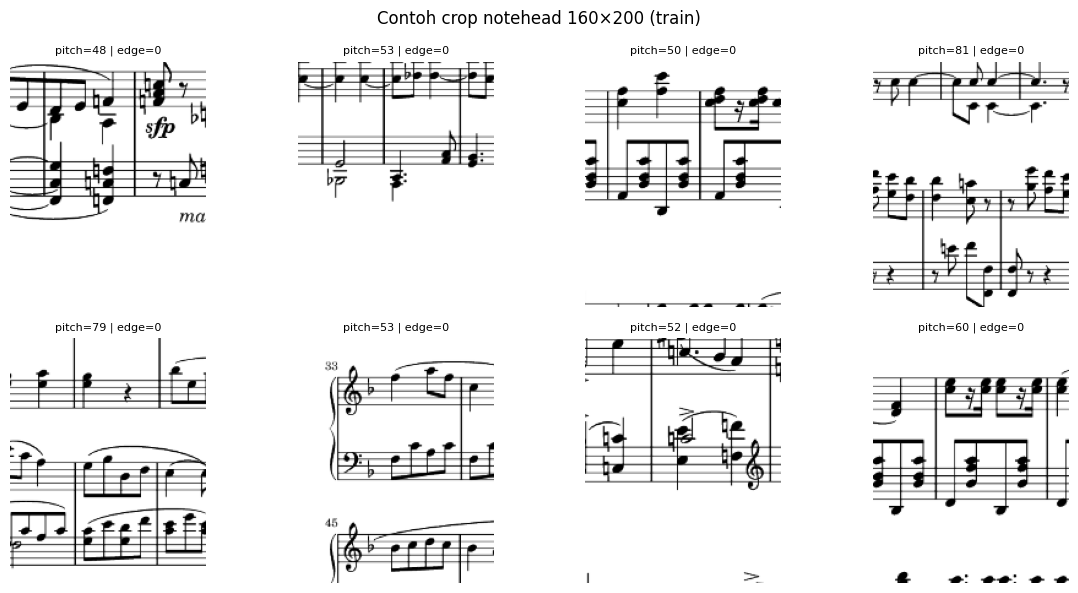

In [9]:
rng = np.random.default_rng(SEED)

idx = rng.choice(len(train_crops), size=min(8, len(train_crops)), replace=False)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(train_crops[i, :, :, 0], cmap="gray", vmin=0, vmax=255)
    row = train_nh.iloc[int(i)]
    ax.set_title(f"pitch={row['pitch']} | edge={row['edge']}", fontsize=8)
    ax.axis("off")
plt.suptitle("Contoh crop notehead 160×200 (train)")
plt.tight_layout()
plt.savefig(FIG / "09_notehead_crops.png", dpi=120, bbox_inches="tight")
plt.show()


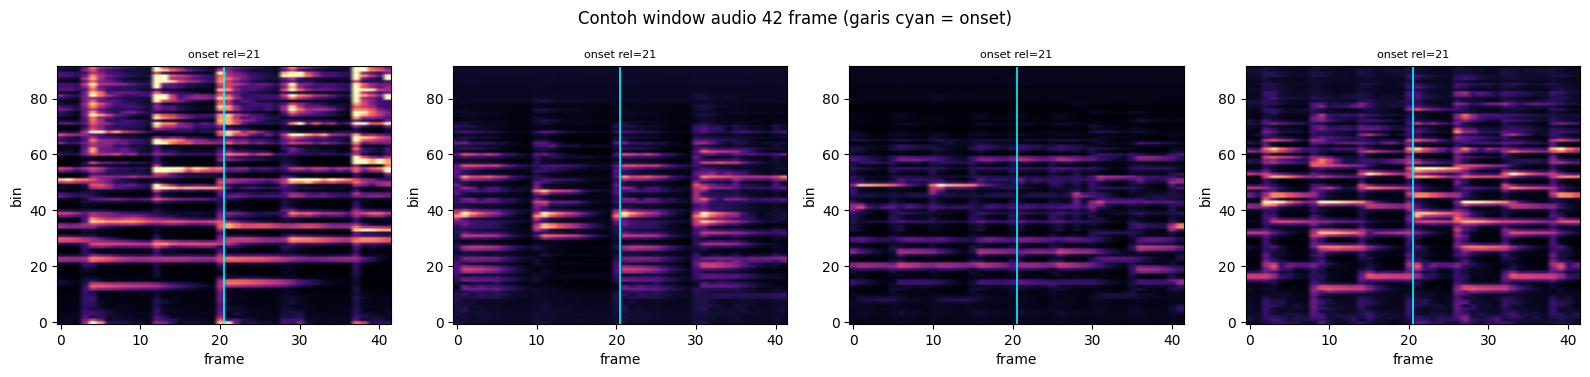

In [10]:
idx = rng.choice(len(train_wins), size=min(4, len(train_wins)), replace=False)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, i in zip(axes, idx):
    w = train_wins[i].astype(np.float32)
    row = train_wd.iloc[int(i)]
    ax.imshow(w.T, aspect="auto", origin="lower", cmap="magma")
    onset_rel = int(row["onset_frame"] - row["start_frame"])
    ax.axvline(onset_rel - 0.5, color="cyan", lw=1.2)
    ax.set_title(f"onset rel={onset_rel}", fontsize=8)
    ax.set_xlabel("frame")
    ax.set_ylabel("bin")
plt.suptitle("Contoh window audio 42 frame (garis cyan = onset)")
plt.tight_layout()
plt.savefig(FIG / "10_audio_windows.png", dpi=120, bbox_inches="tight")
plt.show()


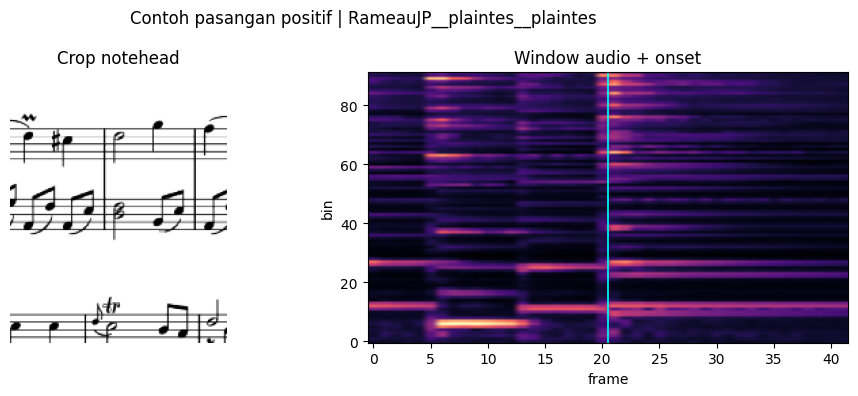

In [11]:
pos = train_pairs[train_pairs["label"] == 1].sample(1, random_state=SEED).iloc[0]
crop_row = int(train_nh.loc[train_nh["notehead_id"] == pos["notehead_id"], "crop_row"].iloc[0])
win_row = int(train_wd.loc[train_wd["window_id"] == pos["window_id"], "window_row"].iloc[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(train_crops[crop_row, :, :, 0], cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Crop notehead")
axes[0].axis("off")

w = train_wins[win_row].astype(np.float32)
row = train_wd.iloc[win_row]
axes[1].imshow(w.T, aspect="auto", origin="lower", cmap="magma")
axes[1].axvline(int(row["onset_frame"] - row["start_frame"]) - 0.5, color="cyan", lw=1.2)
axes[1].set_title("Window audio + onset")
axes[1].set_xlabel("frame")
axes[1].set_ylabel("bin")

plt.suptitle(f"Contoh pasangan positif | {pos['piece']}")
plt.tight_layout()
plt.savefig(FIG / "11_pair_demo.png", dpi=120, bbox_inches="tight")
plt.show()


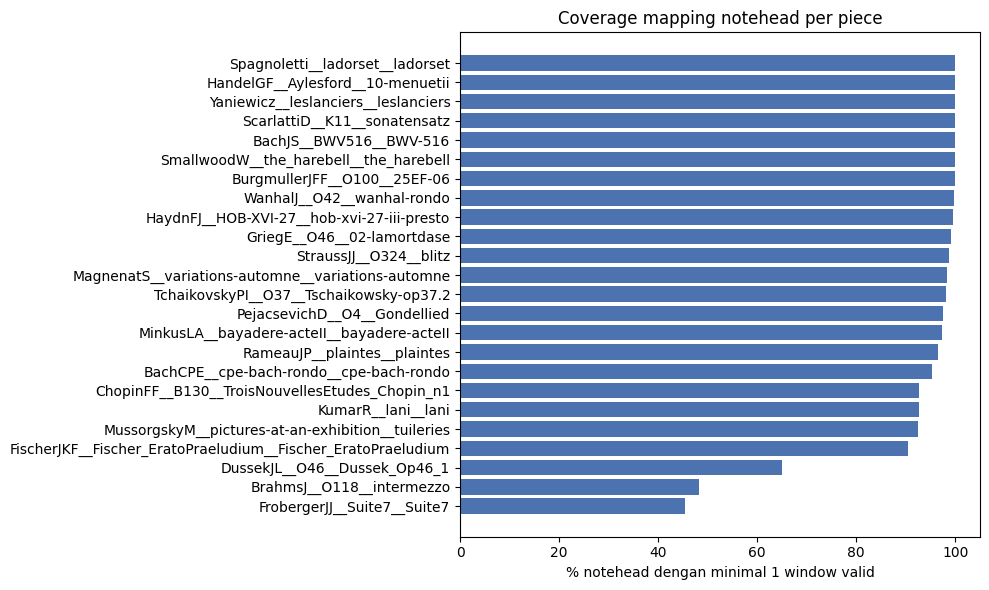

,piece,split,n_noteheads,n_mapped_noteheads,n_valid_windows,pct_mapped
2,FrobergerJJ__Suite7__Suite7,train,1262,572,1144,45.324881
7,BrahmsJ__O118__intermezzo,train,1698,818,1636,48.174323
3,DussekJL__O46__Dussek_Op46_1,train,2133,1387,2774,65.025785
4,FischerJKF__Fischer_EratoPraeludium__Fischer_EratoPraeludium,train,345,312,624,90.434783
10,MussorgskyM__pictures-at-an-exhibition__tuileries,train,682,631,1262,92.521994
23,KumarR__lani__lani,test,752,697,2788,92.686170
21,ChopinFF__B130__TroisNouvellesEtudes_Chopin_n1,test,829,769,3076,92.762364
11,BachCPE__cpe-bach-rondo__cpe-bach-rondo,train,1824,1739,3478,95.339912
15,RameauJP__plaintes__plaintes,train,685,661,1322,96.496350
5,MinkusLA__bayadere-acteII__bayadere-acteII,train,1015,988,1976,97.339901


In [12]:
cov = coverage_all.sort_values("pct_mapped")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(cov["piece"], cov["pct_mapped"], color="#4C72B0")
ax.set_xlabel("% notehead dengan minimal 1 window valid")
ax.set_title("Coverage mapping notehead per piece")
plt.tight_layout()
plt.savefig(FIG / "12_coverage.png", dpi=120, bbox_inches="tight")
plt.show()

display(cov[["piece", "split", "n_noteheads", "n_mapped_noteheads", "n_valid_windows", "pct_mapped"]])


## 8. Demo batch siap training

In [13]:
B = 8
img_idx = rng.choice(len(train_crops), size=B, replace=False)
aud_idx = rng.choice(len(train_wins), size=B, replace=False)

imgs = train_crops[img_idx]
auds = train_wins[aud_idx]

print("Image batch :", imgs.shape, imgs.dtype)
print("Audio batch :", auds.shape, auds.dtype)
print("Image range :", int(imgs.min()), "..", int(imgs.max()))
print("Audio range :", round(float(auds.min()), 3), "..", round(float(auds.max()), 3))


Image batch : (8, 200, 160, 1) uint8
Audio batch : (8, 42, 92) float16
Image range : 0 .. 255
Audio range : -0.907 .. 5.0


In [14]:
summary_note = {
    "crop_w": CROP_W,
    "crop_h": CROP_H,
    "win_frames": WIN_FRAMES,
    "fps": FPS,
    "train_perfs_per_note": TRAIN_PERFS_PER_NOTE,
    "excluded_pieces": sorted(EXCLUDED_PIECES),
    "split_crops": {s: int(len(b[0])) for s, b in split_bundle.items()},
    "split_windows": {s: int(len(b[1])) for s, b in split_bundle.items()},
    "split_pairs": {s: int(len(b[4])) for s, b in split_bundle.items()},
    "image_mean": float(IMG_MEAN),
    "image_std": float(IMG_STD),
    "checks_total": int(len(checks_df)),
    "checks_fail": int((checks_df["status"] == "FAIL").sum()),
}
with open(PROC / "preprocess_summary_note.json", "w", encoding="utf-8") as f:
    json.dump(summary_note, f, indent=2)

display(pd.DataFrame([summary_note]).T.rename(columns={0: "value"}))


,value
crop_w,160
crop_h,200
win_frames,42
fps,20
train_perfs_per_note,2
excluded_pieces,[GobbaertsL__Les_Etoiles_dOr_No1__Les_Etoiles_dOr_No1]
split_crops,"{'train': 14365, 'val': 2430, 'test': 2018}"
split_windows,"{'train': 28730, 'val': 9720, 'test': 8072}"
split_pairs,"{'train': 57460, 'val': 19440, 'test': 16144}"
image_mean,0.893631


## 9. Metodologi dan batasan

**Unit matching.** Satu contoh training = `(crop notehead, window audio di sekitar onset notehead)`. Ini menggantikan pasangan page-level yang terlalu kasar.

**Crop 160×200.** Mengikuti Dorfer et al. (2018). Crop harus memuat garis staff dan not tetangga; notehead saja tidak cukup untuk menentukan pitch.

**Window 42 frame.** Setara ±2,1 detik pada 20 fps. Window dipusatkan di onset; jika keluar batas, padding nol. Ini lebih pendek dari 5 detik karena konteks satu note bersifat lokal.

**Normalisasi.** Crop disimpan mentah uint8; normalisasi gambar dilakukan on-the-fly memakai mean/std crop train. Audio sudah dinormalisasi per bin memakai statistik train dan di-clip ke `[-5, 5]`.

**Negative sampling.** Negatif berasal dari piece lain di split yang sama; 50% dari komposer yang sama sebagai hard negative. Piece dan `work_group` yang sama tidak boleh menjadi negatif.

**Tidak dilakukan.** Tidak ada pitch-shift/time-stretch pada audio karena mengubah isi musikal. Tidak ada flip pada gambar karena partitur tidak invarian terhadap pencerminan. Tidak ada penghapusan garis staff karena garis staff adalah informasi pitch.

**Batasan.**
- Subset hanya 25 piece; hasil retrieval bisa noisy.
- `GobbaertsL__Les_Etoiles_dOr_No1__Les_Etoiles_dOr_No1` tidak punya MuNG dan dikecualikan.
- Banyak notehead tied/missing mapping, terutama Froberger dan Brahms.
- Chord dan repeated note dapat membuat evaluasi exact-match ambigu; evaluasi dapat memakai toleransi onset/page.
- Belum ada raw audio; augmentasi audio terbatas pada domain spektrogram.
